# code_198 · Coverage needs an exchangeable unit and a calibration boundary

**Book:** section 37.3. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_37_GUIDE.md), [execution evidence](../CHAPTER_37_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_198).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Probability and interval contracts identify fitting and calibration roles, uncertainty sources, assessment units and decision costs. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=7898;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 7898


<a id="grouped-classification-sets"></a>
 ## Calibrate whole-building scores and state the coverage event
 Generate 1,000 source, 200 calibration and 300 familiar final buildings, each with three correlated records. Features include severity, load, material and a sensor; shared unobserved building variation affects labels. A separate 300-building shifted cohort has more new material, shifted severity and a changed material-dependent label law. Fit a native histogram classifier only on source. Nonconformity is one minus the probability assigned to the true label. A row-pooled calibration quantile is a diagnostic whose row-exchangeability assumption fails here; the valid grouped construction uses the maximum score across a building's three records, then rank ceil((G+1)(1−alpha)) among G=200 calibration buildings. At alpha=0.1, this is rank181. Include a candidate label if its score is no greater than this threshold. Under exchangeability of calibration and a new building, the marginal event is simultaneous inclusion of all three labels in that new building, not 90% coverage conditional on every feature or regime. The shifted law violates that premise.


,row_coverage,building_all3_coverage,mean_set_size,empty_fraction
Familiar: Building max,0.957778,0.896667,1.624444,0.0
Familiar: Pooled row diagnostic,0.894444,0.723333,1.338889,0.0
Shifted: Building max,0.942222,0.876667,1.702222,0.0
Shifted: Pooled row diagnostic,0.836667,0.693333,1.411111,0.0


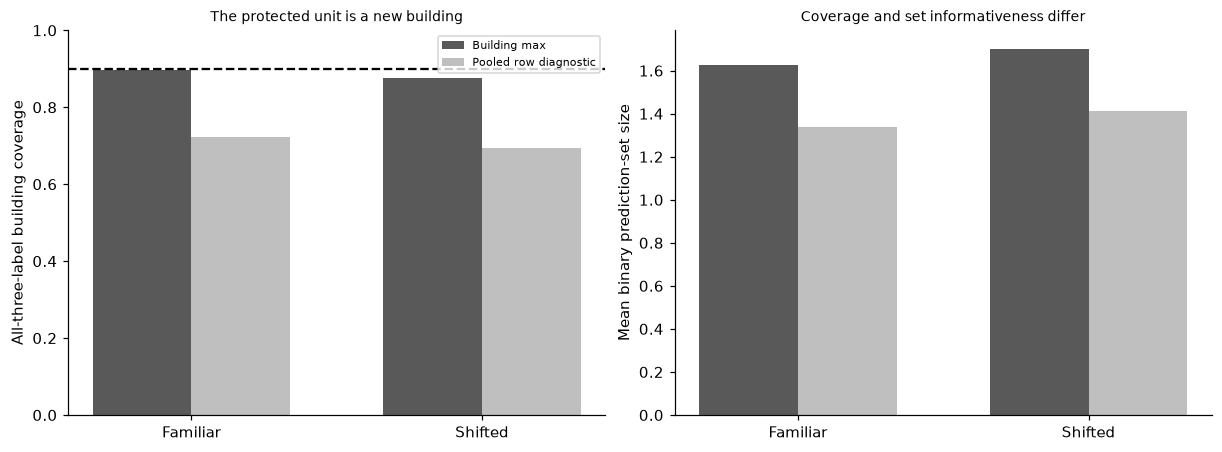

In [2]:
from sklearn.ensemble import HistGradientBoostingClassifier,HistGradientBoostingRegressor
def cohort(groups,shift=False):
    g=np.repeat(np.arange(groups),3);material=rng.binomial(1,.8 if shift else .2,groups)[g];z=rng.normal(loc=.8 if shift else 0,size=groups)[g];load=rng.uniform(0,1.5,groups*3);sensor=rng.normal(size=groups*3);x=np.c_[z,load,material,sensor];frailty=rng.normal(scale=.7,size=groups)[g];logit=-.7+1.5*z+.5*sensor-.5*load+frailty+(3*material if shift else 0);y=rng.binomial(1,expit(logit));burden=1+.4*z+load**2+material+frailty*.3+rng.normal(scale=.2+.2*load,size=groups*3)+(4*material*load**2 if shift else 0);return x,y,burden,g
xs,ys,bs,gs=cohort(1000);xc,yc,bc,gc=cohort(200);xf,yf,bf,gf=cohort(300);xh,yh,bh,gh=cohort(300,True);clf=HistGradientBoostingClassifier(max_iter=100,max_depth=3,early_stopping=False,random_state=SEED).fit(xs,ys);pc=clf.predict_proba(xc);scores=1-pc[np.arange(600),yc];building_scores=scores.reshape(200,3).max(1);alpha=.1
def rank_quantile(s):
    k=int(np.ceil((len(s)+1)*(1-alpha)));return (float(np.sort(s)[k-1]) if k<=len(s) else float('inf')),k
qgroup,kgroup=rank_quantile(building_scores);qrow,krow=rank_quantile(scores);sets={};rows={}
for regime,x,y in [('Familiar',xf,yf),('Shifted',xh,yh)]:
    p=clf.predict_proba(x)
    for method,q in [('Building max',qgroup),('Pooled row diagnostic',qrow)]:
        included=(1-p)<=q;covered=included[np.arange(len(y)),y];key=f'{regime}: {method}';sets[key]=included;rows[key]={'row_coverage':float(covered.mean()),'building_all3_coverage':float(covered.reshape(300,3).all(1).mean()),'mean_set_size':float(included.sum(1).mean()),'empty_fraction':float(np.mean(included.sum(1)==0))};assert np.all((included.sum(1)>=0)&(included.sum(1)<=2))
assert kgroup==181 and len(building_scores)==200;assert qgroup>=qrow;RESULTS.update(building_roles=[1000,200,300,300],records_per_building=3,alpha=alpha,group_rank=kgroup,group_threshold=qgroup,pooled_row_rank=krow,pooled_row_threshold=qrow,classification_set_scores=rows,group_exchangeability_claim='marginal over a new building, simultaneous all three labels',shifted_law_violates_exchangeability=True);display(pd.DataFrame(rows).T);fig,axes=plt.subplots(1,2,figsize=(11,4));xx=np.arange(2)
for j,method in enumerate(['Building max','Pooled row diagnostic']):axes[0].bar(xx+(j-.5)*.34,[rows[f'{regime}: {method}']['building_all3_coverage'] for regime in ['Familiar','Shifted']],width=.34,color=['.35','.75'][j],label=method);axes[1].bar(xx+(j-.5)*.34,[rows[f'{regime}: {method}']['mean_set_size'] for regime in ['Familiar','Shifted']],width=.34,color=['.35','.75'][j],label=method)
axes[0].axhline(.9,color='black',linestyle='--');axes[0].set(xticks=xx,xticklabels=['Familiar','Shifted'],ylim=(0,1),ylabel='All-three-label building coverage',title='The protected unit is a new building');axes[0].legend(fontsize=7);axes[1].set(xticks=xx,xticklabels=['Familiar','Shifted'],ylabel='Mean binary prediction-set size',title='Coverage and set informativeness differ');plt.show()


<a id="grouped-conformal-quantile-intervals"></a>
 ## Conformalize actual quantile fits with a building-level score
 Fit native source quantile regressions at 0.05 and 0.95 for the generated continuous burden. Sort each two-bound prediction before calibration. For each calibration record compute max(lower−y,y−upper), then take the building maximum and the same finite-sample rank. Enlarge each lower/upper boundary by the resulting correction and evaluate row and all-three-record coverage and width on both independent cohorts. This is an original grouped adaptation of conformalized quantile regression; the exchangeability claim concerns a whole new building of the same three-record design. It is not feature-conditional, population-shift or arbitrary-size-building coverage. Visual B1 displays the first twelve fixed familiar records and states the grouped marginal claim separately from the observed outcomes.


,row_coverage,building_all3_coverage,mean_width
Familiar,0.962222,0.896667,1.826304
Shifted,0.434444,0.193333,1.863033


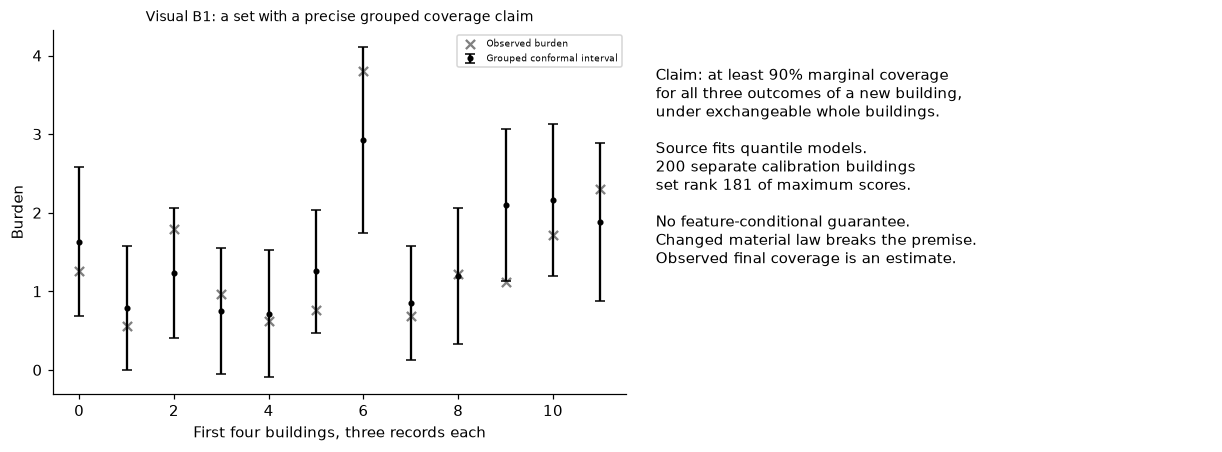

In [3]:
quantile_models=[HistGradientBoostingRegressor(loss='quantile',quantile=t,max_iter=100,max_depth=3,early_stopping=False,random_state=SEED).fit(xs,bs) for t in [.05,.95]]
def raw_bounds(x):return np.sort(np.column_stack([m.predict(x) for m in quantile_models]),axis=1)
qb=raw_bounds(xc);s=np.maximum(qb[:,0]-bc,bc-qb[:,1]).reshape(200,3).max(1);correction,rank=rank_quantile(s);interval_rows={};intervals={}
for regime,x,y in [('Familiar',xf,bf),('Shifted',xh,bh)]:
    b=raw_bounds(x)+np.array([-correction,correction]);covered=(y>=b[:,0])&(y<=b[:,1]);intervals[regime]=b;interval_rows[regime]={'row_coverage':float(covered.mean()),'building_all3_coverage':float(covered.reshape(300,3).all(1).mean()),'mean_width':float(np.mean(b[:,1]-b[:,0]))};assert np.all(b[:,1]>=b[:,0])
assert rank==181 and np.isfinite(correction);RESULTS.update(CQR_group_correction=correction,CQR_rank=rank,CQR_scores=interval_rows);display(pd.DataFrame(interval_rows).T);fig,axes=plt.subplots(1,2,figsize=(11,4));b=intervals['Familiar'][:12];mid=b.mean(1);axes[0].errorbar(np.arange(12),mid,yerr=np.array([mid-b[:,0],b[:,1]-mid]),fmt='o',markersize=3,color='black',capsize=3,label='Grouped conformal interval');axes[0].scatter(np.arange(12),bf[:12],marker='x',color='.5',label='Observed burden');axes[0].set(xlabel='First four buildings, three records each',ylabel='Burden',title='Visual B1: a set with a precise grouped coverage claim');axes[0].legend(fontsize=6);axes[1].axis('off');axes[1].text(.03,.9,'Claim: at least 90% marginal coverage\nfor all three outcomes of a new building,\nunder exchangeable whole buildings.\n\nSource fits quantile models.\n200 separate calibration buildings\nset rank 181 of maximum scores.\n\nNo feature-conditional guarantee.\nChanged material law breaks the premise.\nObserved final coverage is an estimate.',va='top',fontsize=10);plt.show()


<a id="delayed-temporal-recalibration"></a>
 ## A recent-window update is assumption-dependent
 Generate 240 additional three-record buildings arriving in order; after building 80 the probability of drawing the shifted mechanism increases, reaching one by building 160. Source models stay fixed. At arrival i a rolling threshold uses the most recent 80 available building scores; a new building's labels become available only ten arrivals later. Start with the original calibration scores and never read an unavailable label into a threshold. Compare fixed and rolling all-three-label coverage in three predeclared 80-building blocks. This is an executed delayed-calibration heuristic under drift, not a claim of exchangeable conformal coverage or an implementation of a specialized temporal guarantee. Adaptation can lag, lose efficiency or fail. Assessment labels remain available for retrospective reporting after the stream finishes.


,arrivals,fixed_building_coverage,rolling_building_coverage
0,"[0, 79]",0.950,0.8750
1,"[80, 159]",0.900,0.8750
2,"[160, 239]",0.925,0.9125


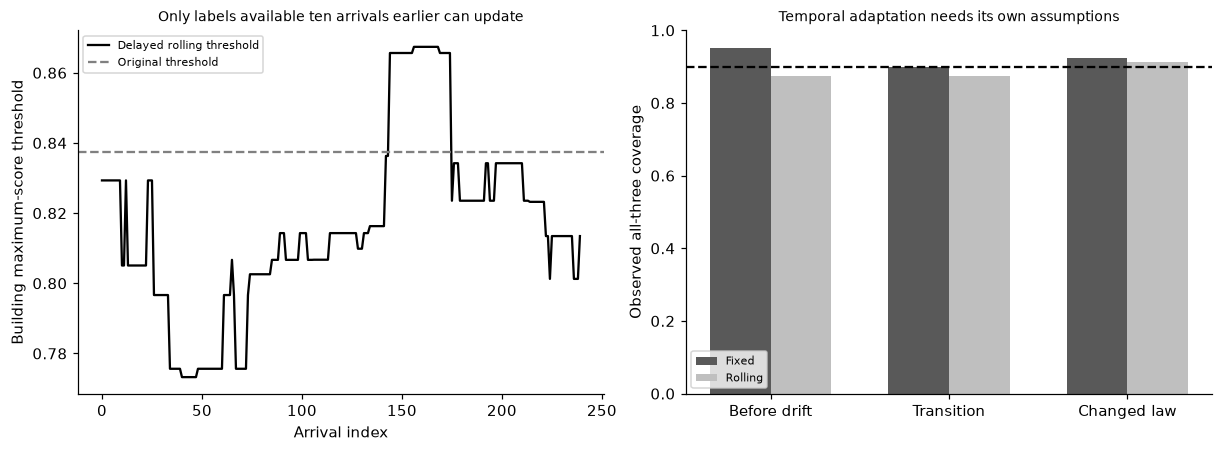

In [4]:
stream_scores=[]
for i in range(240):
    changed=bool(rng.random()<np.clip((i-80)/80,0,1));x,y,_,_=cohort(1,changed);p=clf.predict_proba(x);stream_scores.append(float(np.max(1-p[np.arange(3),y])))
stream_scores=np.array(stream_scores);history=list(building_scores);rolling=[];last_label_used=[]
for i in range(240):
    if i>=10:history.append(float(stream_scores[i-10]))
    threshold,_=rank_quantile(np.array(history[-80:]));rolling.append(threshold);last_label_used.append(i-10 if i>=10 else -1)
rolling=np.array(rolling);fixed_ok=stream_scores<=qgroup;rolling_ok=stream_scores<=rolling;blocks=[{'arrivals':[a,a+79],'fixed_building_coverage':float(fixed_ok[a:a+80].mean()),'rolling_building_coverage':float(rolling_ok[a:a+80].mean())} for a in [0,80,160]];assert all(j<=i-10 for i,j in enumerate(last_label_used) if j>=0);assert len(rolling)==240;RESULTS.update(temporal_blocks=blocks,rolling_window_buildings=80,label_delay_buildings=10,temporal_exchangeability_guarantee_claimed=False);display(pd.DataFrame(blocks));fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].plot(rolling,label='Delayed rolling threshold',color='black');axes[0].axhline(qgroup,color='.5',linestyle='--',label='Original threshold');axes[0].set(xlabel='Arrival index',ylabel='Building maximum-score threshold',title='Only labels available ten arrivals earlier can update');axes[0].legend(fontsize=7);xx=np.arange(3);axes[1].bar(xx-.17,[r['fixed_building_coverage'] for r in blocks],width=.34,color='.35',label='Fixed');axes[1].bar(xx+.17,[r['rolling_building_coverage'] for r in blocks],width=.34,color='.75',label='Rolling');axes[1].axhline(.9,color='black',linestyle='--');axes[1].set(xticks=xx,xticklabels=['Before drift','Transition','Changed law'],ylim=(0,1),ylabel='Observed all-three coverage',title='Temporal adaptation needs its own assumptions');axes[1].legend(fontsize=7);plt.show()


In [5]:
summary={'example_id':'code_198','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual held-out classification nonconformity and building-maximum calibration', 'finite-sample rank with new-building simultaneous versus row-marginal claims', 'actual conformalized quantile intervals and material-shift assessment', 'delayed rolling calibration under drift explicitly without exchangeability guarantee'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual held-out classification nonconformity and building-maximum calibration", "finite-sample rank with new-building simultaneous versus row-marginal claims", "actual conformalized quantile intervals and material-shift assessment", "delayed rolling calibration under drift explicitly without exchangeability guarantee"], "elapsed_seconds": 0.597, "example_id": "code_198", "hardware": "Darwin arm64 CPU", "results": {"CQR_group_correction": 0.2689848610383958, "CQR_rank": 181, "CQR_scores": {"Familiar": {"building_all3_coverage": 0.8966666666666666, "mean_width": 1.8263036302583087, "row_coverage": 0.9622222222222222}, "Shifted": {"building_all3_coverage": 0.19333333333333333, "mean_width": 1.8630334254713918, "row_coverage": 0.43444444444444447}}, "alpha": 0.1, "building_roles": [1000, 200, 300, 300], "classification_set_scores": {"Familiar: Building max": {"building_all3_coverage": 0.8966666666666666, "empty_fraction": 0.0, "mean_set_si